# 02 – Utforsk Fashion-MNIST

**Mål:** Forstå sammenhengen mellom matriser og bilder,
undersøke og visualisere klassefordeling.

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn


## Et gråtonebilde er en matrise med tall

Et digitalt bilde består av **piksler**. I et gråtonebilde
beskriver ett tall lysstyrken til hver piksel. Tallene er ordnet i rader
og kolonner: en **matrise**, som vi kan lagre i en todimensjonal tensor.

Her lager vi et bilde med fire rader og fire kolonner. Med skalaen 0–1
betyr 0 svart, 1 hvitt og verdier imellom ulike gråtoner. `image[row, column]`
velger én piksel. Rad 0 ligger øverst, kolonne 0 lengst til venstre.
Fargebilder trenger flere verdier per piksel, vanligvis rødt, grønt og
blått fordelt på 3 kanaler;

Kjør eksemplet. Sammenlign tallmatrisen med figuren: `imshow` oversetter
verdiene til lysstyrke.


Bildet som tallmatrise:
tensor([[0.0000, 0.0000, 0.0000, 0.0000],
        [0.0000, 0.4000, 0.8000, 0.0000],
        [0.0000, 0.8000, 1.0000, 0.0000],
        [0.0000, 0.0000, 0.0000, 0.0000]])
Piksel i rad 1, kolonne 2: 0.800000011920929


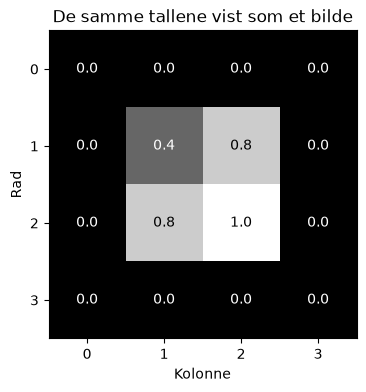

In [3]:
example_image = torch.tensor(
    [
        [0.0, 0.0, 0.0, 0.0],
        [0.0, 0.4, 0.8, 0.0],
        [0.0, 0.8, 1.0, 0.0],
        [0.0, 0.0, 0.0, 0.0],
    ]
)
print("Bildet som tallmatrise:")
print(example_image)
print("Piksel i rad 1, kolonne 2:", example_image[1, 2].item())

fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(example_image, cmap="gray")
for row in range(4):
    for column in range(4):
        value = example_image[row, column].item()
        ax.text(column, row, f"{value:.1f}", ha="center", va="center", color="black" if value > 0.5 else "white")
ax.set_xticks(range(4))
ax.set_yticks(range(4))
ax.set(xlabel="Kolonne", ylabel="Rad", title="De samme tallene vist som et bilde")
plt.show()


## Oppgave 1: Endre én piksel

Hva skjer hvis pikselen i rad 0, kolonne 0 endres
fra 0 til 1? Bruk `clone()` til å lage en uavhengig kopi:

`changed_image = example_image.clone()`

Endre denne pikselen til 1 og vis det nye bildet med
`imshow` og gråtoner.
Skriv også ut den nye matrisen.

<details>
<summary>Hint</summary>

`changed_image[0, 0] = 1.0` endrer øverste venstre piksel.
Bruk figurkoden fra eksemplet.

</details>


In [4]:
changed_image=example_image.clone()

changed_image[0, 0] = 1.0

**Kontroll:** Kjør cellen for å sjekke løsningen.


In [5]:
assert changed_image.shape == example_image.shape, "changed_image skal ha samme form som example_image."
assert changed_image[0, 0].item() == 1.0, "Pikselen øverst til venstre i changed_image skal ha verdien 1.0."
assert example_image[0, 0].item() == 0.0, "example_image skal være uendret. Bruk clone() før du endrer bildet."
assert (changed_image != example_image).sum().item() == 1, "Bare én piksel skal være endret i changed_image."

print("Kontroll bestått!")


Kontroll bestått!


## Ferdig kode: last ned og hent datasettet

Nå skal vi over til å jobbe med faktiske bilder.

Kodesnutten nedenfor laster ned Fashion-MNIST-datasettet til prosjektets `data/`-mappe.

Et **datasett** lar oss hente ett par `(image, label)` med en indeks,
omtrent som fra en liste. `image` inneholder pikselverdiene, og `label`
forteller hvilken type plagg, sko eller veske bildet viser. Vi undersøker ett bilde
om gangen.

Fashion-MNIST inneholder gråtonebilder av klær, sko og vesker i ti klasser.
Etikettene er heltall fra 0 til 9. `CLASS_NAMES[label]` gir det norske klassenavnet.
Vi bruker et utvalg på 20 000 treningsbilder og 1 000 testbilder.


In [6]:
from pytorch_101.utils import CLASS_NAMES, download_fashion_mnist

train_data, test_data = download_fashion_mnist()
print(f"Treningsbilder: {len(train_data)}, testbilder: {len(test_data)}")


Treningsbilder: 20000, testbilder: 1000


## Fra råbilde til bildetensor

Rå Fashion-MNIST-bilder er matriser med 28 rader og 28 kolonner. Hvert tall er
en pikselverdi fra 0 til 255.

Datahjelperen bruker `ToTensor`, som skalerer tallene til 0–1 og legger
til en **kanalakse**. Derfor har bildet formen `[1, 28, 28]`:
én gråtonekanal, 28 rader og 28 kolonner. Klassen lagres separat.
`image[0, row, column]` henter én piksel fra denne ene kanalen.

Cellen under henter råbildet og den skalerte versjonen av samme bilde.
Legg merke til at en liten utskjæring av bildet også bare er tall.


In [7]:
image, label = train_data[0]
original_index = train_data.indices[0]
raw_image = train_data.dataset.data[original_index]
print("Råbilde:", raw_image.shape, raw_image.dtype, raw_image.min().item(), raw_image.max().item())
print("Etter ToTensor():", image.shape, image.dtype, image.min().item(), image.max().item())
print("Klasse:", label, CLASS_NAMES[label])

print("Et utsnitt av matrisen:")
print(image[0, 10:16, 10:16])


Råbilde: torch.Size([28, 28]) torch.uint8 0 255
Etter ToTensor(): torch.Size([1, 28, 28]) torch.float32 0.0 1.0
Klasse: 9 Ankelstøvel
Et utsnitt av matrisen:
tensor([[0.0039, 0.0000, 0.0000, 0.6196, 0.6314, 0.5922],
        [0.0078, 0.0000, 0.0000, 0.5647, 0.5882, 0.5647],
        [0.0078, 0.0000, 0.0039, 0.5294, 0.6157, 0.6549],
        [0.0118, 0.0000, 0.0353, 0.5804, 0.6549, 0.6745],
        [0.0078, 0.0000, 0.1804, 0.5882, 0.6118, 0.6157],
        [0.0000, 0.0000, 0.4510, 0.5373, 0.5882, 0.6000]])


## Oppgave 2: Vis et Fashion-MNIST-bilde

Trekk en tilfeldig indeks i `train_data`, og hent bilde og etikett derfra.
Kall dem `my_image` og
`my_label`. Vis bildet i gråtoner med klassenavnet i tittelen, uten akser.
Skriv også ut form, datatype og minste og største pikselverdi.

<details>
<summary>Hint</summary>

`CLASS_NAMES[my_label]` gir klassenavnet.
`torch.randint(len(train_data), ()).item()` trekker en indeks.
`my_image.squeeze(0)` endrer formen fra `[1, 28, 28]` til `[28, 28]`.

</details>


Form: torch.Size([1, 28, 28])
Datatype: torch.float32
Minste pikselverdi: 0.0
Størts pikselverdi: 1.0


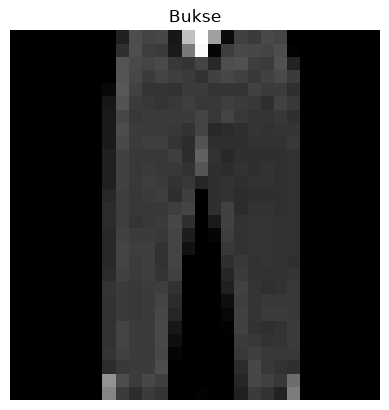

In [8]:
random_index=torch.randint(len(train_data), ()).item()
my_image, my_label=train_data[random_index]

print("Form:", my_image.shape)
print("Datatype:", my_image.dtype)
print("Minste pikselverdi:", my_image.min().item())
print("Størts pikselverdi:", my_image.max().item())

plt.imshow(my_image.squeeze(0), cmap="gray")
plt.title(CLASS_NAMES[my_label])
plt.axis("off")
plt.show()


**Kontroll:** Kjør cellen for å sjekke løsningen.


In [9]:
assert my_image.shape == (1, 28, 28), "my_image skal ha formen (1, 28, 28): én kanal, 28 rader og 28 kolonner."
assert 0 <= my_label <= 9, "my_label skal være en klasseindeks fra 0 til 9."
assert 0 <= my_image.min() <= my_image.max() <= 1, "Pikselverdiene i my_image skal ligge mellom 0 og 1."

print("Kontroll bestått!")


Kontroll bestått!


### Refleksjon

Hva betyr dimensjonene i formen til `my_image`? Hva betyr svart og hvitt med denne fargeskalaen?

Skriv svaret ditt i Markdown-cellen under. Bruk egne resultater der det er relevant.


**Mitt svar:**

(1, 28, 28). 1 kanal, 28 rader, 28 kolonner. Pikselverdier mellom 0 og 1 avhengig av mørkheten på gråtonen. Dermed ser man tydelig konturen av klesplaggene i hvitt, mens rundt er svart. 


## Eksempel: flere bilder i samme figur

Vi bruker `example_image` fra det første bildeeksemplet.

`subplots` lager flere akser. `ravel()` gir oss en flat liste av aksene, slik
at vi kan bruke en vanlig løkke. Hver akse får sitt eget bilde og sin egen tittel.


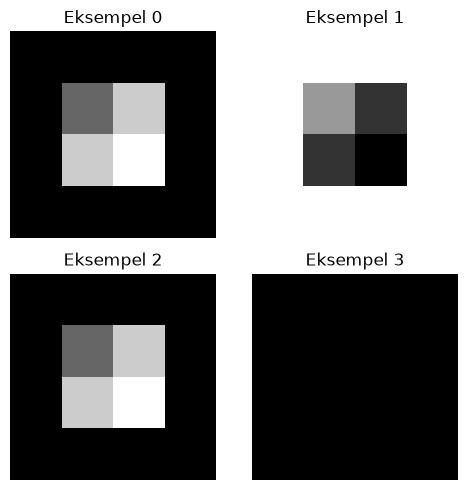

In [10]:
example_images = [example_image, 1 - example_image, example_image.T, torch.zeros_like(example_image)]
fig, axes = plt.subplots(2, 2, figsize=(5, 5))
for index, ax in enumerate(axes.ravel()):
    ax.imshow(example_images[index], cmap="gray")
    ax.set_title(f"Eksempel {index}")
    ax.axis("off")
fig.tight_layout()
plt.show()


## Oppgave 3: Lag et bilderutenett

Lag en figur med 3 × 3 akser. Trekk ni forskjellige treningsbilder og vis dem med riktig
klassenavn over hvert bilde. Bruk samme gråtoneskala i alle rutene.

<details>
<summary>Hint</summary>

Bruk `torch.randperm(len(train_data))[:9].tolist()` for ni ulike indekser.
Kombiner dem med aksene ved hjelp av `zip(axes.ravel(), image_indices)`.

</details>


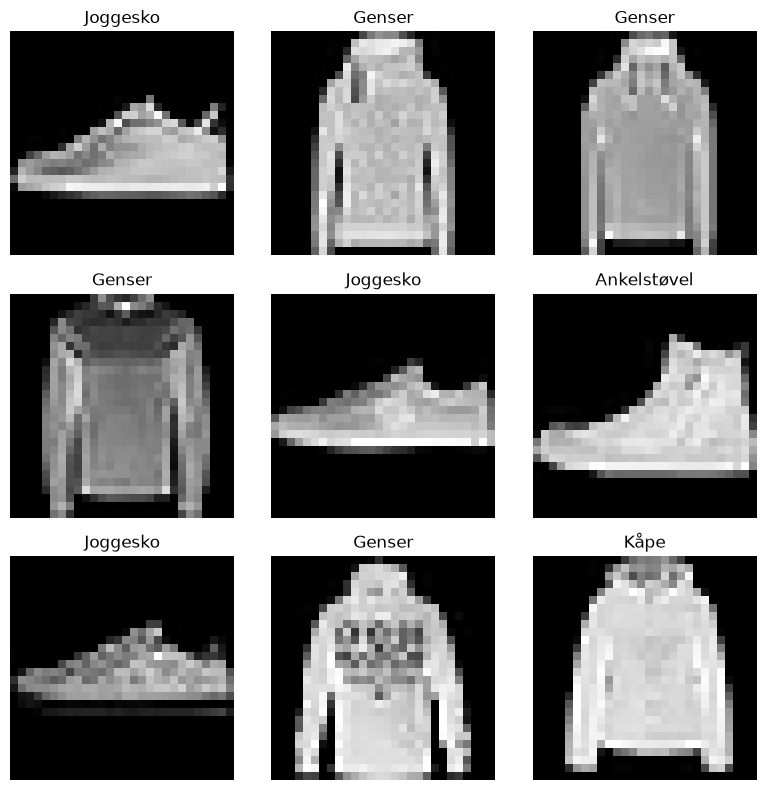

In [11]:
import matplotlib.pyplot as plt
import torch

image_indices=torch.randperm(len(train_data))[:9].tolist()

fig, axes=plt.subplots(3, 3, figsize=(8,8))

for ax, index in zip(axes.ravel(), image_indices):
    my_image, my_label=train_data[index]

    ax.imshow(my_image.squeeze(0), cmap="gray", vmin=0, vmax=1)
    ax.set_title(CLASS_NAMES[my_label])
    ax.axis("off")

plt.tight_layout()
plt.show()

## Eksempel: tell kategorier og tegn et stolpediagram

Klasse-labels er kategorier. Fordelingen kan vises i et stolpediagram.

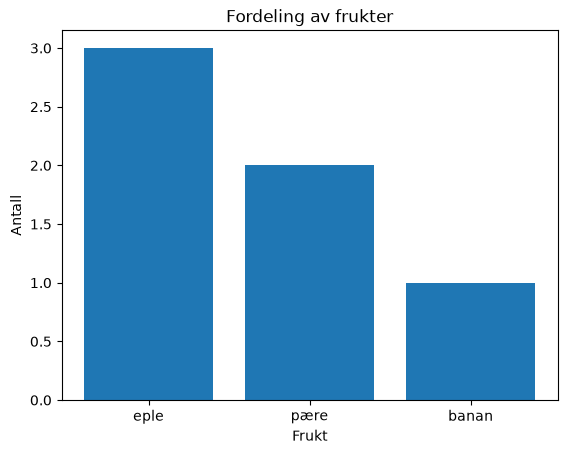

In [12]:
fruits = ["eple", "pære", "eple", "banan", "pære", "eple"]
categories = ["eple", "pære", "banan"]
fruit_counts = [fruits.count(category) for category in categories]
fig, ax = plt.subplots()
ax.bar(categories, fruit_counts)
ax.set(xlabel="Frukt", ylabel="Antall", title="Fordeling av frukter")
plt.show()


## Oppgave 4: Undersøk klassefordelingen

Tell hvor mange bilder det er av hver klasse i **treningsutvalget**.
Lag listen `class_counts` med ti tall, der indeks 0 er antall bilder av T-skjorter/topper.
Lag et stolpediagram med klassenavn på x-aksen og antall bilder på y-aksen.
Vis alle ti klassenavnene langs x-aksen. Skriv også ut antallene.

<details>
<summary>Hint</summary>

Start med `class_counts = [0] * 10`. For hvert `image, label` i datasettet:
øk `class_counts[label]` med 1. Bruk `range(10)` som stolpenes posisjoner.
`ax.set_xticks(range(10), CLASS_NAMES, rotation=45, ha="right")` viser navnene.
Bruk `fig.tight_layout()` for å få plass til dem.

</details>

Finn også `majority_class` og `baseline_accuracy`: hvilken nøyaktighet får
en modell som alltid gjetter den vanligste klassen i treningsutvalget, målt på treningsutvalget?


Antall bilder per klasse: [0, 0, 0, 0, 0, 0, 0, 0, 0, 1]
Vanligste klasse: 9
Klassenavn: Ankelstøvel


AttributeError: module 'matplotlib.pyplot' has no attribute 'shox'

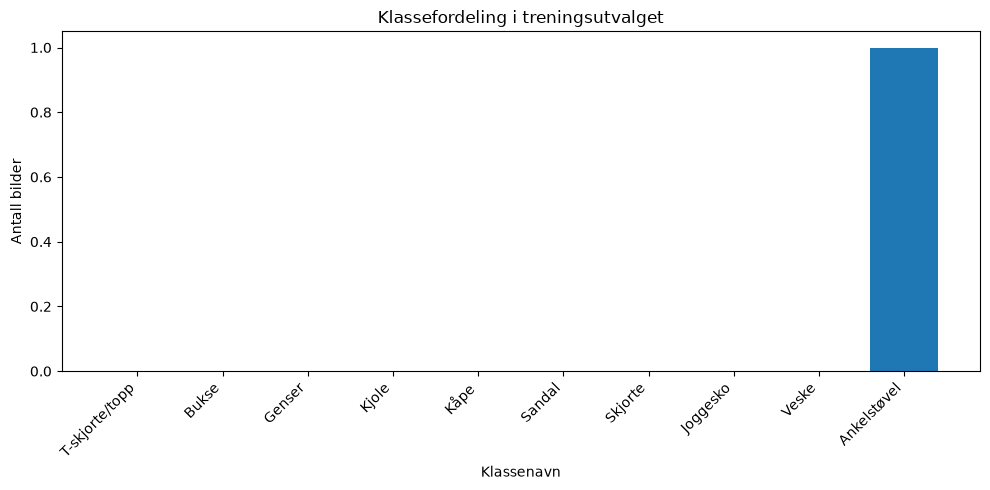

In [ ]:
class_counts = [0]*10

for image, label in train_data:
    class_counts[label]+=1

    majority_class = max(range(10), key=lambda i: class_counts[i])
    baseline_accuracy=max(class_counts)/len(train_data)

    print("Antall bilder per klasse:", class_counts)
    print("Vanligste klasse:", majority_class)
    print("Klassenavn:", CLASS_NAMES[majority_class])

    fig, ax=plt.subplots(figsize=(10,5))

    ax.bar(range(10), class_counts)

    ax.set_xticks(range(10), CLASS_NAMES, rotation=45, ha="right")
    ax.set_xlabel("Klassenavn")
    ax.set_ylabel("Antall bilder")
    ax.set_title("Klassefordeling i treningsutvalget")

    fig.tight_layout()
    plt.show()
    
    



**Kontroll:** Kjør cellen for å sjekke løsningen.


In [ ]:
assert len(class_counts) == 10, "class_counts skal inneholde ett antall for hver av de ti klassene."
assert sum(class_counts) == len(train_data), "Summen av class_counts skal være lik antall bilder i train_data."
assert all(count > 0 for count in class_counts), "Alle klassene skal ha minst ett bilde. Sjekk hvordan du teller etikettene."

assert majority_class == max(range(10), key=lambda class_index: class_counts[class_index]), (
    "majority_class skal være indeksen til klassen med flest bilder."
)
assert baseline_accuracy == max(class_counts) / len(train_data), (
    "baseline_accuracy skal være antallet i største klasse delt på antall treningsbilder."
)

print("Kontroll bestått!")


NameError: name 'train_data' is not defined

### Refleksjon

1. Hvilken klasse forekommer oftest og sjeldnest? Oppgi begge antallene fra din kjøring.
2. Er fordelingen omtrent jevn? Hvorfor kan en svært skjev fordeling være et problem
ved trening og når vi rapporterer samlet nøyaktighet?
3. Hvorfor er flertallsgjetting en nyttig referanse?

Skriv svaret ditt i Markdown-cellen under. Bruk egne resultater der det er relevant.



**Mitt svar:**

Skriv din forklaring her.


## Referanser

- [PyTorch – Datasets & DataLoaders](https://docs.pytorch.org/tutorials/beginner/basics/data_tutorial.html)
